# 01 — Análisis exploratorio de datos (EDA)
**Proyecto:** Clasificación de calidad de frutas — Algoritmos y Programación III, Icesi 2026-2
**Fase CRISP-DM:** 2. Comprensión de los datos
**Responsable:** Samuel Cifuentes

**Objetivo:** entender el dataset *Fruit Quality Classification* (Kaggle) antes de preprocesar y modelar:
1. ¿Cuántas imágenes hay por fruta y por calidad? ¿Hay desbalance?
2. ¿Cómo se ven las imágenes de cada clase?
3. ¿Qué tamaños (resolución) tienen las imágenes?
4. ¿El color y el brillo diferencian las frutas buenas de las malas?

> **Requisito:** el dataset debe estar descomprimido en `data/raw/` (ver README).

## 0. Librerías y rutas

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

sns.set_theme(style="whitegrid")
random.seed(42)
np.random.seed(42)

# Rutas relativas a la carpeta notebooks/
RAW_DIR = Path("../data/raw")
FIG_DIR = Path("../experiments/results/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def guardar(fig, nombre, vectorial=True):
    """Guarda la figura en PNG y, si es una gráfica, también en SVG (vectorial, para el informe)."""
    fig.savefig(FIG_DIR / f"{nombre}.png", dpi=150 if vectorial else 80, bbox_inches="tight")
    if vectorial:
        fig.savefig(FIG_DIR / f"{nombre}.svg", bbox_inches="tight")

## 1. Inventario del dataset
El dataset viene organizado en 3 carpetas:
- `Good Quality_Fruits/<Fruta>_Good` → una fruta de **buena** calidad por imagen.
- `Bad Quality_Fruits/<Fruta>_Bad` → frutas de **mala** calidad.
- `Mixed Qualit_Fruits/<Fruta>` → **varias** frutas de calidades distintas en la misma foto (se usarán luego para recortes).

Recorremos todas las carpetas y armamos una tabla (`DataFrame`) con una fila por imagen.

In [2]:
CARPETAS = {
    "Good Quality_Fruits": "good",
    "Bad Quality_Fruits": "bad",
    "Mixed Qualit_Fruits": "mixed",
}
# Unificamos nombres de frutas (en Mixed el limón aparece como "Lemon")
NOMBRE_FRUTA = {"Apple": "apple", "Banana": "banana", "Guava": "guava",
                "Lime": "lime", "Lemon": "lime", "Orange": "orange",
                "Pomegranate": "pomegranate"}
EXTENSIONES = {".jpg", ".jpeg", ".png"}

filas = []
for carpeta, calidad in CARPETAS.items():
    for sub in sorted((RAW_DIR / carpeta).iterdir()):
        if not sub.is_dir():
            continue
        fruta = NOMBRE_FRUTA[sub.name.split("_")[0]]
        for f in sub.iterdir():
            if f.suffix.lower() in EXTENSIONES:
                filas.append({"path": str(f), "fruit": fruta, "quality": calidad})

df = pd.DataFrame(filas)
print(f"Total de imágenes: {len(df):,}")
df.head()

Total de imágenes: 19,526


,path,fruit,quality
0,../data/raw/Good Quality_Fruits/Apple_Good/201...,apple,good
1,../data/raw/Good Quality_Fruits/Apple_Good/201...,apple,good
2,../data/raw/Good Quality_Fruits/Apple_Good/201...,apple,good
3,../data/raw/Good Quality_Fruits/Apple_Good/201...,apple,good
4,../data/raw/Good Quality_Fruits/Apple_Good/201...,apple,good


## 2. Distribución de clases

In [3]:
tabla = pd.crosstab(df["fruit"], df["quality"], margins=True, margins_name="Total")
tabla = tabla[["good", "bad", "mixed", "Total"]]
tabla

quality,good,bad,mixed,Total
fruit,,,,
apple,1149,1141,113,2403
banana,1113,1087,285,2485
guava,1152,1129,148,2429
lime,1094,1085,278,2457
orange,1216,1159,125,2500
pomegranate,5940,1187,125,7252
Total,11664,6788,1074,19526


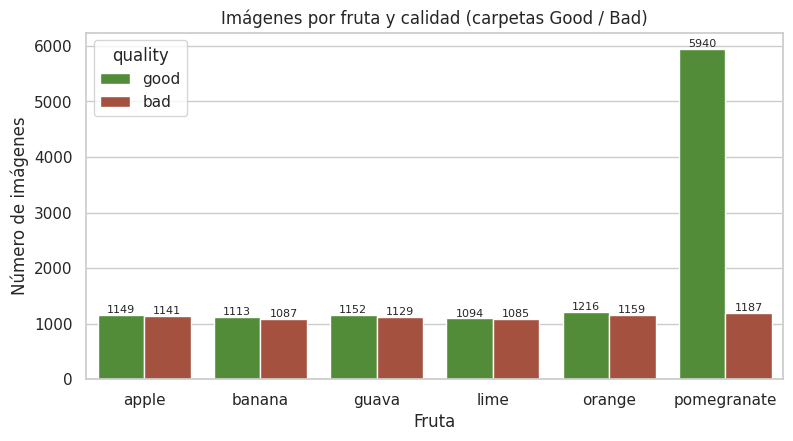

In [4]:
df_gb = df[df["quality"] != "mixed"]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(data=df_gb, x="fruit", hue="quality", hue_order=["good", "bad"],
              palette={"good": "#4C9A2A", "bad": "#B5462F"}, ax=ax)
ax.set_title("Imágenes por fruta y calidad (carpetas Good / Bad)")
ax.set_xlabel("Fruta"); ax.set_ylabel("Número de imágenes")
for c in ax.containers:
    ax.bar_label(c, fontsize=8)
guardar(fig, "01_distribucion_clases")
plt.show()

In [5]:
# Desbalance: razón entre la clase más grande y la más pequeña
conteo = df_gb.groupby(["fruit", "quality"]).size()
print(conteo.sort_values(ascending=False).head(3))
print(f"\nRazón de desbalance (máx/mín): {conteo.max() / conteo.min():.2f}")
print(f"Proporción global good/bad: {(df_gb.quality=='good').mean():.1%} / {(df_gb.quality=='bad').mean():.1%}")

fruit        quality
pomegranate  good       5940
orange       good       1216
pomegranate  bad        1187
dtype: int64

Razón de desbalance (máx/mín): 5.47
Proporción global good/bad: 63.2% / 36.8%


**Interpretación:**
- Las clases están más o menos balanceadas (≈1.100 imágenes) **excepto granada buena**, que tiene ≈5 veces más imágenes.
- Si no se corrige, los modelos tenderían a predecir "granada buena" con más frecuencia. En la fase de preparación se hará **submuestreo** de esa clase (o pesos de clase).
- La clase **regular** no existe en el dataset original: se construirá re-etiquetando (ver `docs/guia_etiquetado.md`).

## 3. Ejemplos visuales por clase

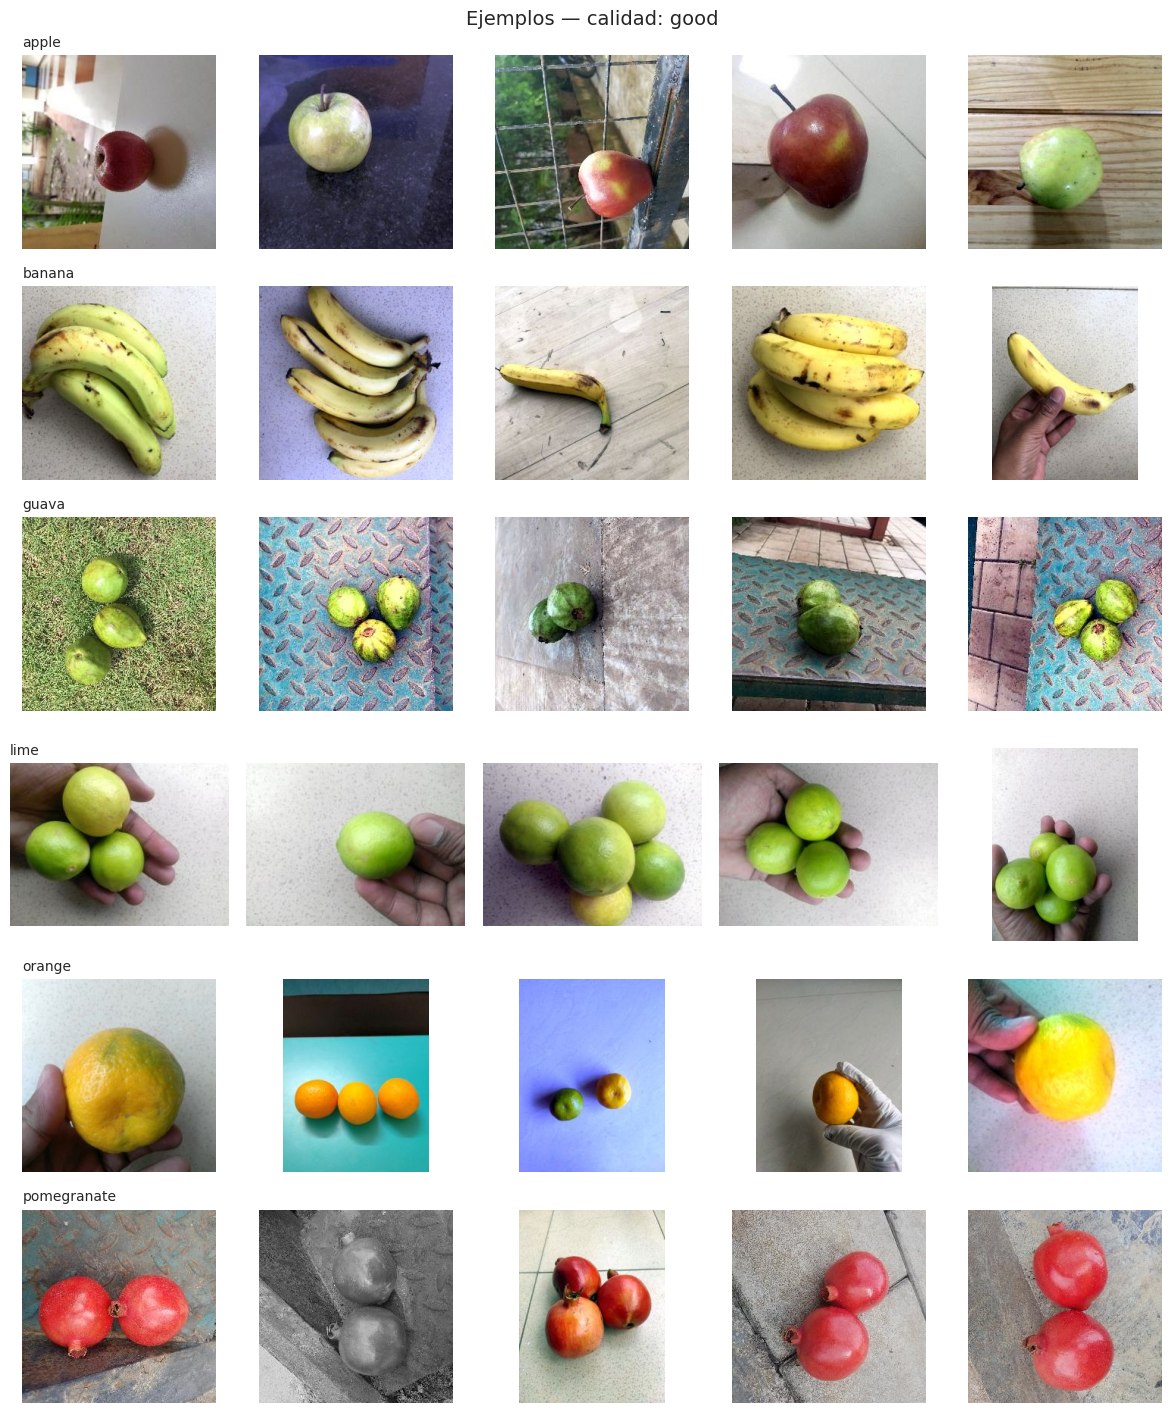

In [6]:
def mostrar_ejemplos(calidad, n=5, sz=3):
    frutas = sorted(df["fruit"].unique())
    fig, axes = plt.subplots(len(frutas), n, figsize=(n * sz * 0.8, len(frutas) * sz * 0.8))
    for i, fruta in enumerate(frutas):
        muestras = df[(df.fruit == fruta) & (df.quality == calidad)].sample(n, random_state=1)
        for j, p in enumerate(muestras["path"]):
            ax = axes[i, j]
            im = Image.open(p).convert("RGB")
            im.thumbnail((256, 256))  # reducimos para que sea rápido (hay fotos de 8000x6000)
            ax.imshow(im)
            ax.axis("off")
            if j == 0:
                ax.set_title(fruta, loc="left", fontsize=10)
    fig.suptitle(f"Ejemplos — calidad: {calidad}", fontsize=14)
    fig.tight_layout()
    guardar(fig, f"02_ejemplos_{calidad}", vectorial=False)  # fotos: solo PNG
    plt.show()

mostrar_ejemplos("good")

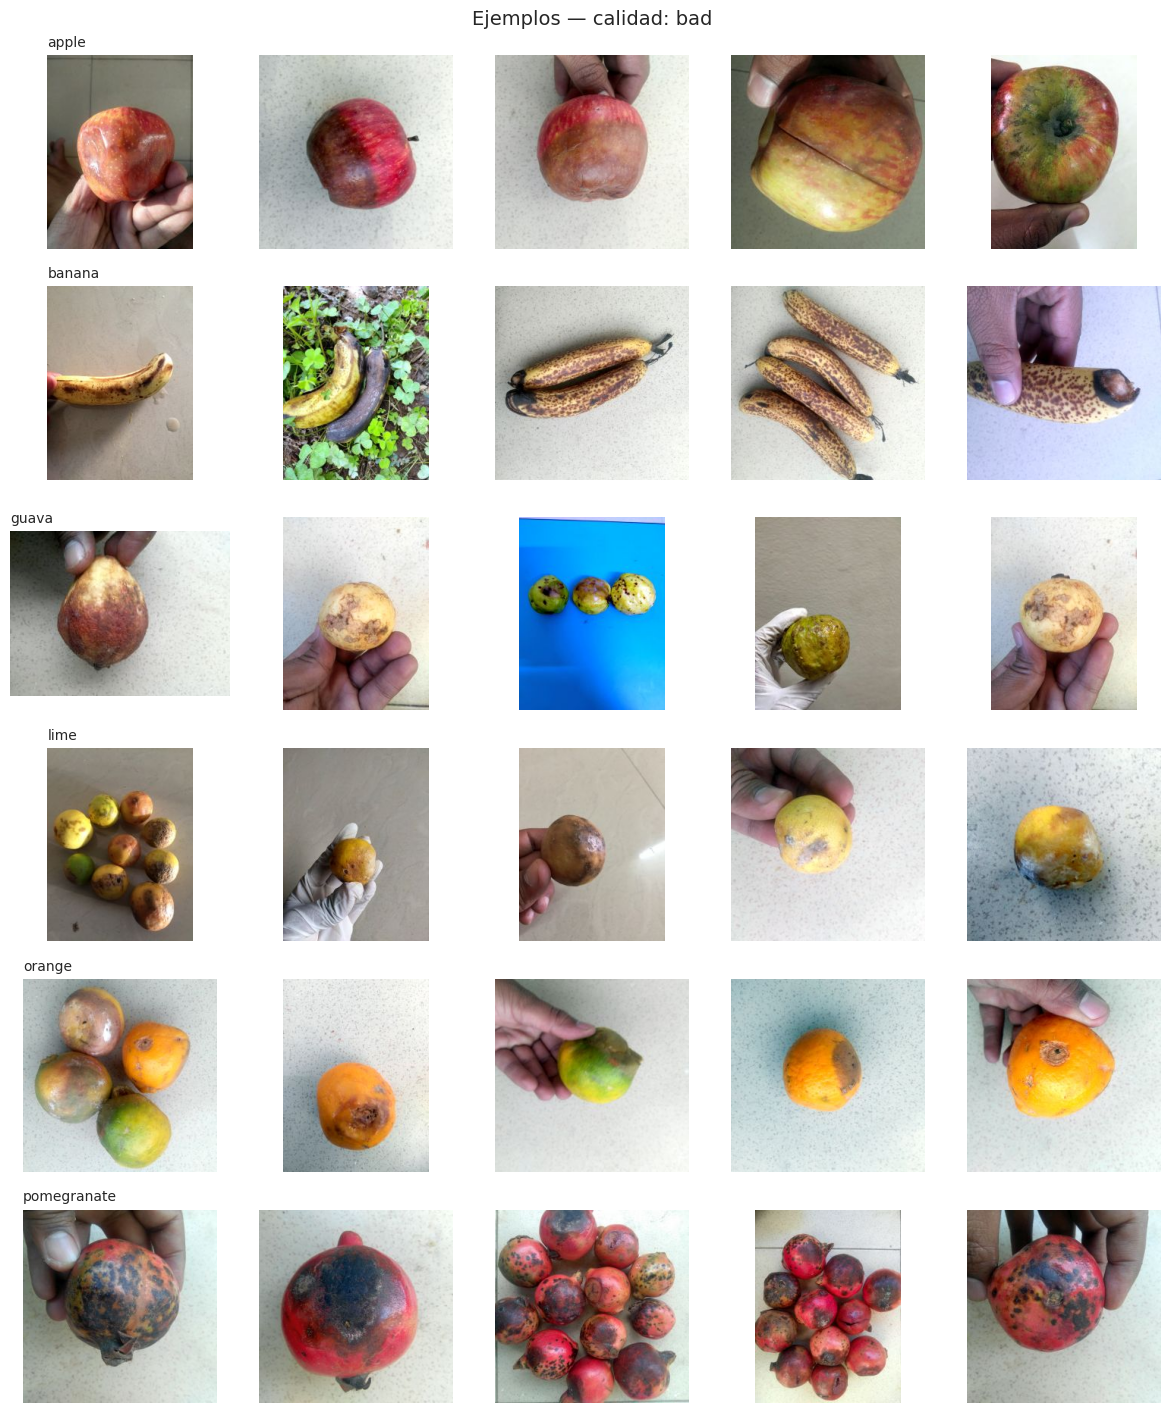

In [7]:
mostrar_ejemplos("bad")

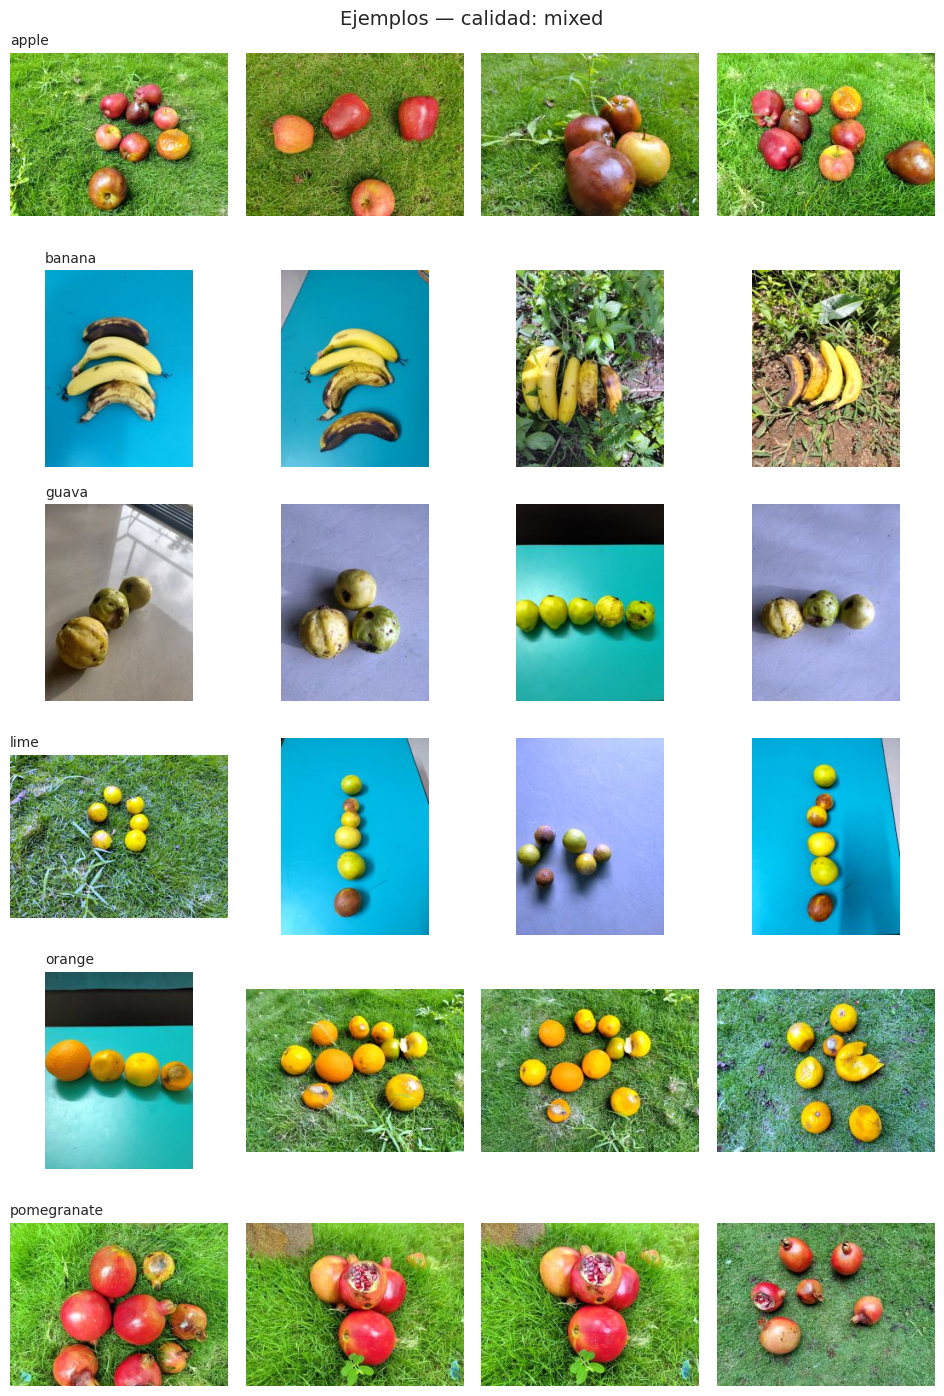

In [8]:
mostrar_ejemplos("mixed", n=4)

**Observaciones visuales:**
- Las fotos tienen fondos variados (piso, mesa, tela azul) y muchas veces aparece la **mano** sosteniendo la fruta → ruido que el modelo debe aprender a ignorar.
- En *Bad* hay defectos de severidad muy distinta: desde un punto pequeño hasta podredumbre total → justifica crear la clase **regular**.
- En *Mixed* hay varias frutas por foto y fondos difíciles (pasto) → se necesitan recortes individuales.

## 4. Resolución de las imágenes
Leemos solo el encabezado de cada imagen (`Image.open` no carga los píxeles), por lo que es rápido.

In [9]:
def leer_tamano(p):
    try:
        with Image.open(p) as im:
            return im.size  # (ancho, alto)
    except Exception:
        return (np.nan, np.nan)  # imagen corrupta

# Leer ~19.500 encabezados toma unos minutos: guardamos el resultado en caché (CSV)
CACHE_TAM = FIG_DIR / "cache_tamanos.csv"
if CACHE_TAM.exists():
    cache = pd.read_csv(CACHE_TAM)
else:
    tamanos = df["path"].apply(leer_tamano)
    cache = pd.DataFrame({"path": df["path"], "width": [t[0] for t in tamanos],
                          "height": [t[1] for t in tamanos]})
    cache.to_csv(CACHE_TAM, index=False)
df = df.merge(cache, on="path", how="left")

print("Imágenes corruptas:", df["width"].isna().sum())
df["resolucion"] = df["width"].astype("Int64").astype(str) + "x" + df["height"].astype("Int64").astype(str)
df["resolucion"].value_counts().head(10)

Imágenes corruptas: 0


resolucion
256x256      12508
192x256       4536
256x192       1897
3000x4000      381
8000x6000      183
144x256         12
256x144          9
Name: count, dtype: int64

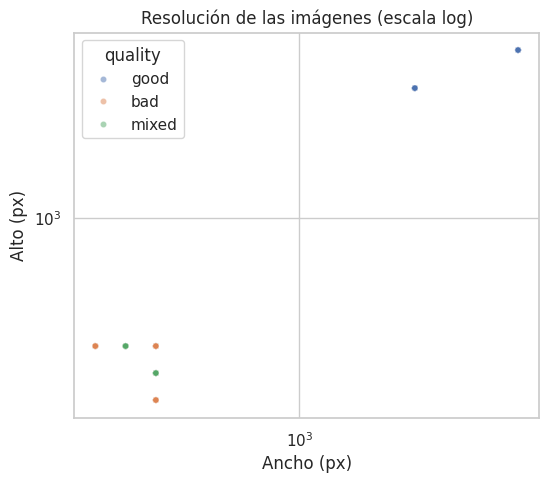

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(data=df, x="width", y="height", hue="quality", alpha=0.5, s=20, ax=ax)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Resolución de las imágenes (escala log)")
ax.set_xlabel("Ancho (px)"); ax.set_ylabel("Alto (px)")
guardar(fig, "03_resoluciones")
plt.show()

**Interpretación:** la gran mayoría de imágenes son de **256×256** (o 192×256), pero hay algunas muy grandes (hasta 8000×6000), sobre todo en *Mixed*. Todas se **redimensionarán a un tamaño fijo** (p. ej. 128×128) en el preprocesamiento, porque tanto la CNN como la extracción de características necesitan entradas del mismo tamaño.

## 5. Color y brillo: ¿separan buenas de malas?
Para cada imagen (muestra de 150 por clase y fruta) calculamos en el espacio de color **HSV**:
- **H (tono):** el "color" (rojo, amarillo, verde…).
- **S (saturación):** qué tan intenso es el color.
- **V (valor/brillo):** qué tan clara u oscura es la imagen.

Hipótesis: las frutas malas tienen zonas oscuras/marrones → **menor brillo y saturación**.

In [11]:
def stats_hsv(p, sz=64):
    im = Image.open(p)
    im.draft("RGB", (sz * 2, sz * 2))  # decodifica JPG a menor resolución (más rápido)
    im = im.convert("RGB").resize((sz, sz)).convert("HSV")
    a = np.asarray(im, dtype=np.float32) / 255.0   # normalizamos a [0, 1]
    return a[..., 0].mean(), a[..., 1].mean(), a[..., 2].mean()

muestra = (df_gb.groupby(["fruit", "quality"], group_keys=False)
                .apply(lambda g: g.sample(min(150, len(g)), random_state=0)))
CACHE_HSV = FIG_DIR / "cache_hsv.csv"
if CACHE_HSV.exists():
    muestra = muestra.merge(pd.read_csv(CACHE_HSV), on="path", how="left")
else:
    hsv = np.array([stats_hsv(p) for p in muestra["path"]])
    muestra = muestra.assign(H=hsv[:, 0], S=hsv[:, 1], V=hsv[:, 2])
    muestra[["path", "H", "S", "V"]].to_csv(CACHE_HSV, index=False)
muestra.groupby(["fruit", "quality"])[["H", "S", "V"]].mean().round(3)

/sessions/rcw-01am4fibgx7h2gfh7cf4adhr/tmp/ipykernel_11/2297392352.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(150, len(g)), random_state=0)))


H      S      V
fruit       quality                     
apple       bad      0.350  0.267  0.686
            good     0.335  0.372  0.561
banana      bad      0.252  0.197  0.717
            good     0.363  0.286  0.705
guava       bad      0.274  0.216  0.706
            good     0.396  0.268  0.613
lime        bad      0.306  0.214  0.655
            good     0.451  0.217  0.691
orange      bad      0.312  0.244  0.770
            good     0.274  0.370  0.629
pomegranate bad      0.331  0.248  0.670
            good     0.287  0.278  0.580

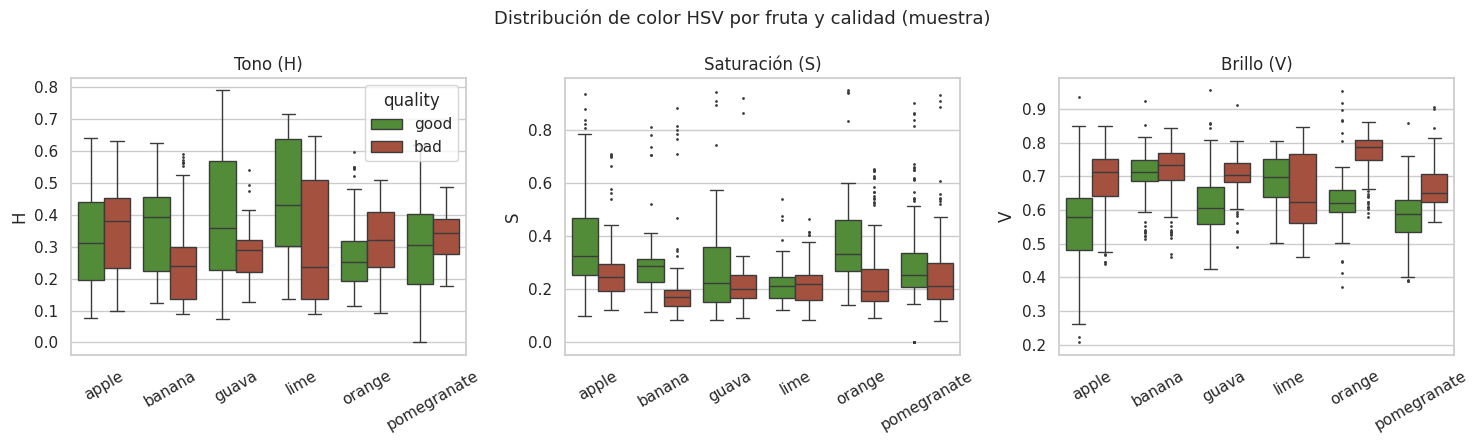

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=False)
for ax, canal, nombre in zip(axes, ["H", "S", "V"], ["Tono (H)", "Saturación (S)", "Brillo (V)"]):
    sns.boxplot(data=muestra, x="fruit", y=canal, hue="quality", hue_order=["good", "bad"],
                palette={"good": "#4C9A2A", "bad": "#B5462F"}, ax=ax, fliersize=1)
    ax.set_title(nombre); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
    if ax is not axes[0]:
        ax.get_legend().remove()
fig.suptitle("Distribución de color HSV por fruta y calidad (muestra)", fontsize=13)
fig.tight_layout()
guardar(fig, "04_hsv_por_clase")
plt.show()

In [13]:
# Diferencia promedio (good - bad) por fruta: valores positivos = las buenas son más brillantes/saturadas
medias = muestra.groupby(["fruit", "quality"])[["S", "V"]].mean().unstack()
diff = pd.DataFrame({
    "ΔS (good-bad)": medias[("S", "good")] - medias[("S", "bad")],
    "ΔV (good-bad)": medias[("V", "good")] - medias[("V", "bad")],
}).round(3)
diff

,ΔS (good-bad),ΔV (good-bad)
fruit,,
apple,0.105,-0.125
banana,0.089,-0.012
guava,0.052,-0.093
lime,0.003,0.036
orange,0.126,-0.141
pomegranate,0.030,-0.090


**Interpretación:**
- **Saturación (S):** en las 6 frutas las buenas son **más saturadas** que las malas (ΔS > 0, hasta +0,13 en naranja). Tiene sentido: la podredumbre y las manchas marrones "apagan" el color. → La saturación es una **característica útil**.
- **Brillo (V):** al contrario de lo esperado, las imágenes malas son **más brillantes** en casi todas las frutas (ΔV < 0). Como estas estadísticas se calcularon sobre **toda la imagen** (fruta + fondo), la explicación más probable es que las fotos malas se tomaron sobre fondos más claros.
- **Conclusión importante:** el fondo está **correlacionado con la clase** → un modelo podría aprender a distinguir *fondos* en lugar de *frutas* (sesgo / atajo). Por eso: (1) las características de color deben calcularse **solo sobre la fruta segmentada**, y (2) hay que validar con fotos propias en fondo uniforme.

## 6. Resumen

In [14]:
print(f"Total imágenes: {len(df):,}")
print(f"Frutas: {sorted(df.fruit.unique())}")
print(df.quality.value_counts().to_string())
print(f"Imágenes corruptas: {df.width.isna().sum()}")

Total imágenes: 19,526
Frutas: ['apple', 'banana', 'guava', 'lime', 'orange', 'pomegranate']
quality
good     11664
bad       6788
mixed     1074
Imágenes corruptas: 0


## Conclusiones del EDA
1. **Tamaño:** 19.526 imágenes de 6 frutas, sin imágenes corruptas: 11.664 *good*, 6.788 *bad* y 1.074 fotos *mixed* con varias frutas.
2. **Desbalance:** granada buena tiene 5.940 imágenes, ≈5,5× la clase más pequeña. Globalmente 63 % *good* vs 37 % *bad* → se aplicará submuestreo de granada buena y/o pesos de clase, y se usará **F1-macro** además de accuracy.
3. **Resoluciones heterogéneas:** 64 % son 256×256, pero hay 564 fotos de 3000×4000 y 8000×6000 → redimensionar todas a un tamaño fijo.
4. **Fondos y manos:** fondos variados y manos en muchas fotos. El análisis HSV muestra que las fotos malas tienen fondos más claros → **riesgo de que el modelo aprenda el fondo**. Mitigación: segmentar la fruta, calcular características solo sobre ella y evaluar con fotos propias en fondo liso.
5. **Color:** la **saturación** separa buenas de malas en las 6 frutas → buena característica para los modelos de ML clásico (Juan Camilo), siempre calculada sobre la fruta segmentada.
6. **Clase regular:** el dataset solo tiene 2 calidades y en *Bad* conviven defectos leves y graves → se re-etiquetará una muestra como *regular* (ver `docs/guia_etiquetado.md`).

**Siguiente paso (fase 3 — preparación):** segmentación de la fruta, recortes de *Mixed*, re-etiquetado de *regular*, redimensionamiento, normalización, balanceo y división train/val/test.